# Lifespan Predictor — Training Demo on NASA Turbofan Data

Predict **time to event** from histories in which some subjects have
not had the event yet. Here the subjects are aircraft engines from
NASA's C-MAPSS dataset, and the event is failure: the model predicts
each engine's remaining useful life.

The notebook runs end to end with no edits. It downloads the public
dataset, tunes and trains a model on SageMaker, shows its scores and calibration,
runs a batch transform and a real-time endpoint, and deletes what it made.

It runs on either Lifespan Predictor product, including the **free
tier**: FD001 has 100 training engines, within the free
tier's cap of 100 units. See [Which product?](https://github.com/kooditurva/lifespan-predictor-sdk#which-product)
for the two products and their algorithm ARNs.

**What you need**: an active AWS Marketplace subscription to either
product, and a SageMaker execution role.

## 1. Install the SDK

The client SDK is installed from its GitHub release tag. It is not
published to PyPI.

In [ ]:
# Other releases: https://github.com/kooditurva/lifespan-predictor-sdk/releases
!pip install -q "lifespan-predictor @ git+https://github.com/kooditurva/lifespan-predictor-sdk@v1.1.0"

## 2. Point at the algorithm you subscribed to

The ARN below is the free tier's, in `eu-west-1`. If you subscribed to
the other product or work in another Region, use the ARN listed under
[Which product?](https://github.com/kooditurva/lifespan-predictor-sdk#which-product), or find it in the AWS Marketplace
console: **Manage subscriptions**, select the product, choose
**Continue to configuration**, and pick your Region.

The execution role is the IAM role SageMaker assumes to run your
training jobs. The SDK reads it from `SAGEMAKER_ROLE_ARN`. Outside
SageMaker Studio, set that variable before starting Jupyter; in Studio,
the cell below sets it from `get_execution_role()`.

In [2]:
import os

import matplotlib.pyplot as plt

from lifespan_predictor_sdk import (
    CategoricalRange,
    ContinuousRange,
    SurvivalModel,
    download_nasa_dataset,
    get_nasa_test_dataframe,
    get_nasa_train_dataframe,
)

ALGORITHM_ARN = 'arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e'

if 'SAGEMAKER_ROLE_ARN' not in os.environ:
    from sagemaker import get_execution_role

    os.environ['SAGEMAKER_ROLE_ARN'] = get_execution_role()

### Check your setup

What the SDK will use. Set `SAGEMAKER_BUCKET` to keep the data and models
in a bucket of your own; otherwise SageMaker's default bucket for your
account and Region is used, and created if needed.

In [3]:
from importlib.metadata import version

import boto3

region = boto3.Session().region_name
arn_region = ALGORITHM_ARN.split(':')[3]

print('SDK version:        ', version('lifespan-predictor'))
print('Region:             ', region)
print('AWS_PROFILE:        ', os.environ.get('AWS_PROFILE', '(not set)'))
print('SAGEMAKER_ROLE_ARN: ', os.environ['SAGEMAKER_ROLE_ARN'])
print('SAGEMAKER_BUCKET:   ', os.environ.get(
    'SAGEMAKER_BUCKET', "(not set: SageMaker's default bucket)"))
print('Algorithm ARN:      ', ALGORITHM_ARN)

if region != arn_region:
    print(f'Warning: the session is in {region}, but the algorithm is in '
          f'{arn_region}. Use the ARN for your Region.')

SDK version:         1.1.0
Region:              eu-west-1
AWS_PROFILE:         (not set)
SAGEMAKER_ROLE_ARN:  arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker
SAGEMAKER_BUCKET:    kooditurva-lifespan-predictor-buyer-ci
Algorithm ARN:       arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e


## 3. Load the NASA turbofan data

FD001 is one of the four C-MAPSS sub-datasets: simulated engines, each
observed once per flight cycle until it fails. The SDK downloads it and
returns it in the shape the algorithm expects:

| column | meaning |
|---|---|
| `unit` | the engine |
| `cycles` | the flight cycle within its history: `1, 2, 3, …` |
| `duration`, `event` | how long it ran, and whether it failed |
| everything else | operating settings and sensor readings |

The test engines' histories stop before failure. `test_labels_df` holds
their true remaining life, one row per engine, to score against.

In [4]:
data_dir = 'data/nasa'
download_nasa_dataset(data_dir, datasets=[1])

train_df = get_nasa_train_dataframe(data_dir, datasets=[1])
test_df, test_labels_df = get_nasa_test_dataframe(data_dir, datasets=[1])

print(f"Training: {train_df['unit'].nunique()} engines, {len(train_df)} rows")
print(f"Test:     {test_df['unit'].nunique()} engines, {len(test_df)} rows")
train_df.head()

Training: 100 engines, 20631 rows
Test:     100 engines, 13096 rows


,unit,cycles,setting_1,setting_2,setting_3,f1,f2,f3,f4,f5,...,f15,f16,f17,f18,f19,f20,f21,group,duration,event
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8.4195,0.03,392,2388,100.0,39.06,23.4190,0,192,1
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8.4318,0.03,392,2388,100.0,39.00,23.4236,0,191,1
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8.4178,0.03,390,2388,100.0,38.95,23.3442,0,190,1
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8.3682,0.03,392,2388,100.0,38.88,23.3739,0,189,1
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8.4294,0.03,393,2388,100.0,38.90,23.4044,0,188,1


## 4. Tune and train

`fit()` submits a SageMaker training job against the subscribed
algorithm. Nothing about the model runs locally.

A range where a value would go makes the job tune: it tries `n_trials`
configurations drawn from the ranges, scores each by cross-validation on
the training engines, then trains the model on the best one. It all
happens inside the one training job.

- `num_nodes`, `learning_rate` and `dropout` are tuned: the network's
  layer sizes, how fast it learns, and how much it is regularised.
- `model_type='deepsurv'` trains DeepSurv, a neural network that
  generalises the Cox proportional hazards model.
- `rolling_means` adds windowed averages of each sensor, which helps when
  signals drift before failure.
- `max_rul` caps the remaining life the model learns to predict.
- `calibration='isotonic'` calibrates the predicted probabilities on the
  validation split, which `val_split` holds out from the training engines.

Passing the test set and its labels makes the training job score the
model on them before it finishes.

In [5]:
model = SurvivalModel({
    'algorithm_arn': ALGORITHM_ARN,
    'model_type': 'deepsurv',
    'instance_type': 'ml.m5.large',
    'epochs': 30,
    'rolling_means': [5, 10, 20, 30],
    'max_rul': 125,
    'calibration': 'isotonic',
    # n_trials is the number of configurations tried. Each is scored on 5
    # cross-validation folds, so the job trains about 5 x n_trials times
    # before the final model: raise it to search more, lower it to finish sooner.
    'n_trials': 6,
    'num_nodes': CategoricalRange([[24], [32, 32]]),
    'learning_rate': ContinuousRange(1e-4, 1e-2, log=True),
    'dropout': ContinuousRange(0.0, 0.4),
    # To train once without tuning, give plain values in place of the ranges
    # and leave out n_trials, e.g. 'num_nodes': [24], 'learning_rate': 0.01,
    # 'dropout': 0.1.
})

model.fit(train_df, val_split=0.2, test_df=test_df, test_labels_df=test_labels_df)

val_split=0.2: 80 train units, 20 val units (16608 train rows, 4023 val rows)


🚀 Starting SageMaker training...


📦 S3 bucket: kooditurva-lifespan-predictor-buyer-ci
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker
🔖 Algorithm ARN: arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e
📤 Uploading raw CSV data to S3...
  ✓ Saved train.csv (16608 rows)


  ✓ Saved val.csv (4023 rows)
  ✓ Saved test.csv (13096 rows)
  ✓ Saved test_labels.csv (100 rows)


✓ Raw CSV uploaded to: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/training-1793213001
⚙️  Configuring training job...
📋 Training config keys: ['model_type', 'max_rul', 'epochs', 'rolling_means', 'calibration', 'n_trials', 'num_nodes', 'learning_rate', 'dropout', 'sdk_version']
📋 Config size: 401 chars


...

Training seconds: 309
Billable seconds: 309


✓ Training completed!

Training Job Summary:
  Name: survival-model-2026-10-28-18-43-23-603
  Status: Completed
  Training Time: 309 seconds
  Billable Time: 309 seconds
  Instance Type: ml.m5.large
  Model artifacts: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-18-43-23-603/output/model.tar.gz
  Debug output: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output
  Hyperparameters: 1 configured

  Final Metrics:
    test:c_index: 0.8712
    test:rmse: 13.7315


✓ Training job: survival-model-2026-10-28-18-43-23-603
✓ Model artifact: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-18-43-23-603/output/model.tar.gz
📥 Downloading training metrics...


✓ Test C-index: 0.8712
✓ Test RMSE: 13.7315
✓ Calibration bias: 0.0048 (well-calibrated)
✓ IBS: 0.0590 (excellent)


✓ tuning_trials loaded: 6 trials
✓ Training complete!


### The tuning trials

Each trial's values, and its C-index on each cross-validation fold with
their mean. The trial with the highest mean is the one the model was
trained with.

In [6]:
import pandas as pd
from IPython.display import display

trials = model.get_tuning_trials()
best = trials.get_best_trial()

for trial in trials:
    values = ', '.join(
        f'{name}={value:.3g}' if isinstance(value, float) else f'{name}={value}'
        for name, value in trial.params.items())
    print(f"Trial {trial.number}{' (best)' if trial is best else ''}: {values}")
    scores = trial.fold_scores()
    if not scores:
        print(f'  {trial.state}, no fold scores')
        continue
    folds = [f'fold {i}' for i in range(1, len(scores) + 1)]
    table = pd.DataFrame([[*scores, trial.value]], columns=[*folds, 'mean'],
                         index=['C-index'])
    display(table.round(3))

Trial 0 (best): num_nodes=[32, 32], learning_rate=0.00291, dropout=0.239


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.924,0.908,0.911,0.912,0.916,0.914


Trial 1: num_nodes=[24], learning_rate=0.000131, dropout=0.346


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.899,0.885,0.863,0.895,0.887,0.886


Trial 2: num_nodes=[32, 32], learning_rate=0.00011, dropout=0.388


...

,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.915,0.891,0.897,0.902,0.911,0.903


Trial 4: num_nodes=[32, 32], learning_rate=0.000731, dropout=0.116


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.92,0.904,0.91,0.907,0.921,0.912


Trial 5: num_nodes=[24], learning_rate=0.000384, dropout=0.147


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
C-index,0.918,0.899,0.898,0.908,0.908,0.906


## 5. Results

The training job's scores on the test engines:

- **C-index** measures ranking: given two engines, how often does the
  model put the one that failed first at higher risk? `0.5` is a coin flip.
- **RMSE** is the error in predicted remaining life, in cycles.
- The **calibration curve** compares predicted failure probabilities with
  how often engines actually failed by then. A calibrated model follows
  the diagonal.

=== Evaluation Metrics ===
  Scored on 100 units. 11 have a true remaining life beyond max_rul=125, the
  horizon the model predicts: RMSE counts them as 125, and the C-indices and
  IBS treat them as censored at 125. Calibration bias uses the 89 that
  failed within max_rul=125.
  C-index (IPCW):       0.8712  (higher is better, 0.5 = random; corrected for censoring)
  C-index (Harrell):    0.8712  (uncorrected; the tuning metric)
  C-index (Antolini):   0.8712  (higher is better, time-dependent)
  RMSE:                 13.7315  (lower is better)
  IBS:                  0.0590  (lower is better, <0.1 = excellent)  (excellent)
  Calibration bias:     0.0048  (closer to 0 is better)  (well-calibrated)
Prediction arrays not available (e.g. SageMaker backend).


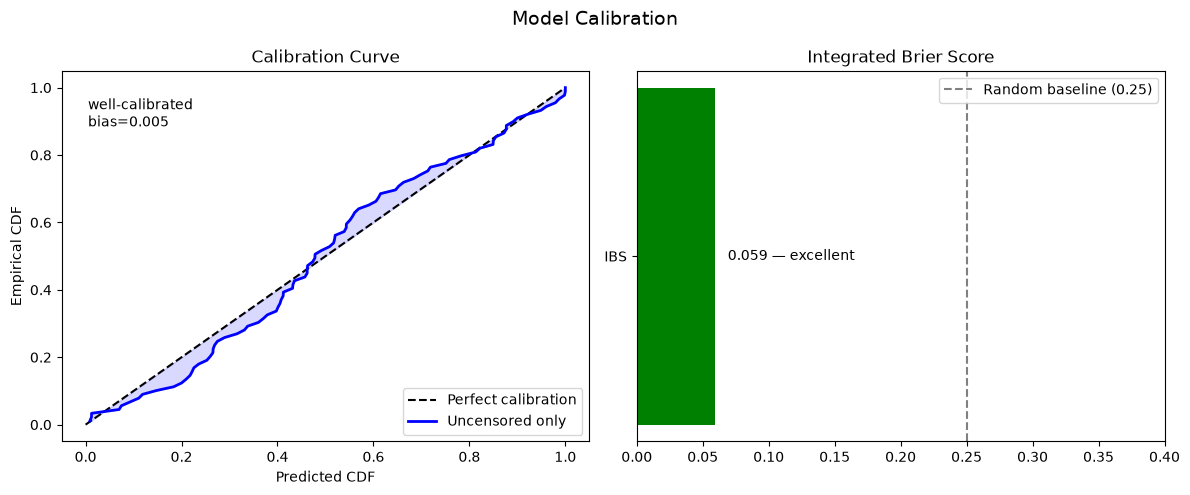

In [7]:
model.get_evaluation_result().report()

### Training history

Training and validation loss per epoch, and the learning rate.

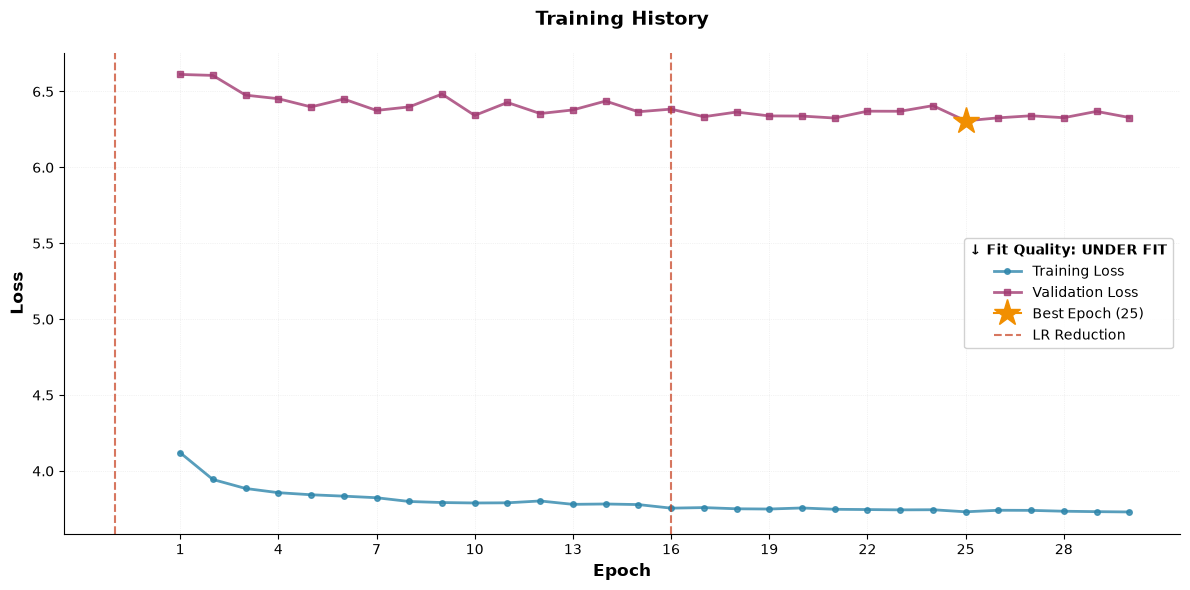

In [8]:
model.get_training_log().plot()
plt.show()

In [9]:
model.print_training_job_summary()


Training Job Summary:
  Name: survival-model-2026-10-28-18-43-23-603
  Status: Completed
  Training Time: 309 seconds
  Billable Time: 309 seconds
  Instance Type: ml.m5.large
  Model artifacts: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-18-43-23-603/output/model.tar.gz
  Debug output: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output
  Hyperparameters: 1 configured

  Final Metrics:
    test:c_index: 0.8712
    test:rmse: 13.7315


## 6. Create a SageMaker model

`deploy()` turns the trained estimator into a SageMaker **Model**, which
is what batch transform runs against. Section 9 hosts it on a real-time
endpoint as well.

In [10]:
model_name = model.deploy()
print('Created SageMaker model:', model_name)

🚀 Creating SageMaker Model for batch transform...
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker


📦 Model name: deepsurv-2026-10-28-18-50-11-234
✅ Model created successfully!
   Ready for batch transform inference

Next steps:
  mean_times = model.predict_mean(test_df)

Created SageMaker model: deepsurv-2026-10-28-18-50-11-234


## 7. Batch transform

`predict()` runs a batch transform job and returns, for each engine, the
probability of still running after each number of further cycles: one
column per engine, indexed by time. Each engine is predicted from the
end of its history.

🔮 Running batch transform for mean survival predictions...
   Input: 13096 samples
📤 Uploading input data to S3...


✓ Input uploaded: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/batch-input-1793213463/input.csv


🏃 Starting batch transform job...
   Instance: ml.m5.large (count: 1)


.

.

...

[2026-10-28 18:55:41 +0000] [1] [INFO] Starting gunicorn 26.2.0
[2026-10-28 18:55:41 +0000] [1] [INFO] Listening at: http://0.0.0.0:8080 (1)
[2026-10-28 18:55:41 +0000] [1] [INFO] Starting gunicorn 26.2.0
[2026-10-28 18:55:41 +0000] [1] [INFO] Listening at: http://0.0.0.0:8080 (1)
[2026-10-28 18:55:41 +0000] [1] [INFO] Using worker: sync
[2026-10-28 18:55:41 +0000] [7] [INFO] Booting worker with pid: 7
[2026-10-28 18:55:41 +0000] [1] [INFO] Control socket listening at /root/.gunicorn/gunicorn.ctl
Starting model loading in background thread...
Loading model from /opt/ml/model...
[2026-10-28 18:55:41 +0000] [1] [INFO] Using worker: sync
[2026-10-28 18:55:41 +0000] [7] [INFO] Booting worker with pid: 7
[2026-10-28 18:55:41 +0000] [1] [INFO] Control socket listening at /root/.gunicorn/gunicorn.ctl
Starting model loading in background thread...
Loading model from /opt/ml/model...
Loading model from /opt/ml/model
✓ Model loaded successfully
  Model type: deepsurv
  Features: 120
✓ Model load

2026-10-28T18:55:51.357:[sagemaker logs]: MaxConcurrentTransforms=1, MaxPayloadInMB=6, BatchStrategy=MULTI_RECORD


✅ Batch transform complete!
📥 Downloading results from S3...


   Found 1 output file(s)


✓ Results downloaded: 100 predictions
100 survival curves, one per test engine


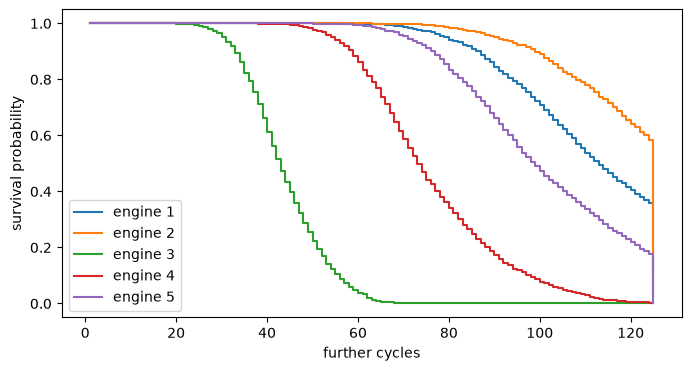

In [11]:
curves = model.predict(test_df)
units = sorted(test_df['unit'].unique())
print(f'{curves.shape[1]} survival curves, one per test engine')

ax = curves.iloc[:, :5].plot(drawstyle='steps-post', figsize=(8, 4))
ax.set_xlabel('further cycles')
ax.set_ylabel('survival probability')
ax.legend([f'engine {u}' for u in units[:5]])
plt.show()

## 8. Score it

`evaluate()` scores the deployed model's predictions against the true
remaining life in `test_labels_df`. It runs its own batch transform, and
should agree with the training job's scores in section 5.

Every metric scores every test engine, and the report says how. The
model predicts no further than `max_rul`, so an engine whose true
remaining life is beyond it counts as censored at `max_rul` for the
C-indices and the IBS, and RMSE compares its prediction with `max_rul`.
Calibration bias uses the engines that failed within `max_rul`. The
API reference's `EvaluationResult` entry explains each choice.

🔮 Running batch transform for mean survival predictions...
   Input: 13096 samples
📤 Uploading input data to S3...


✓ Input uploaded: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/batch-input-1793213774/input.csv


🏃 Starting batch transform job...
   Instance: ml.m5.large (count: 1)


.

.

...

[2026-10-28 19:00:59 +0000] [1] [INFO] Starting gunicorn 26.2.0
[2026-10-28 19:00:59 +0000] [1] [INFO] Listening at: http://0.0.0.0:8080 (1)
[2026-10-28 19:00:59 +0000] [1] [INFO] Using worker: sync
[2026-10-28 19:00:59 +0000] [7] [INFO] Booting worker with pid: 7
[2026-10-28 19:00:59 +0000] [1] [INFO] Control socket listening at /root/.gunicorn/gunicorn.ctl
Starting model loading in background thread...
Loading model from /opt/ml/model...
Loading model from /opt/ml/model
✓ Model loaded successfully
  Model type: deepsurv
  Features: 120
✓ Model loaded successfully


2026-10-28T19:01:09.852:[sagemaker logs]: MaxConcurrentTransforms=1, MaxPayloadInMB=6, BatchStrategy=MULTI_RECORD


✅ Batch transform complete!
📥 Downloading results from S3...


   Found 1 output file(s)


✓ Results downloaded: 100 predictions
C-index: 0.871
RMSE:    13.7


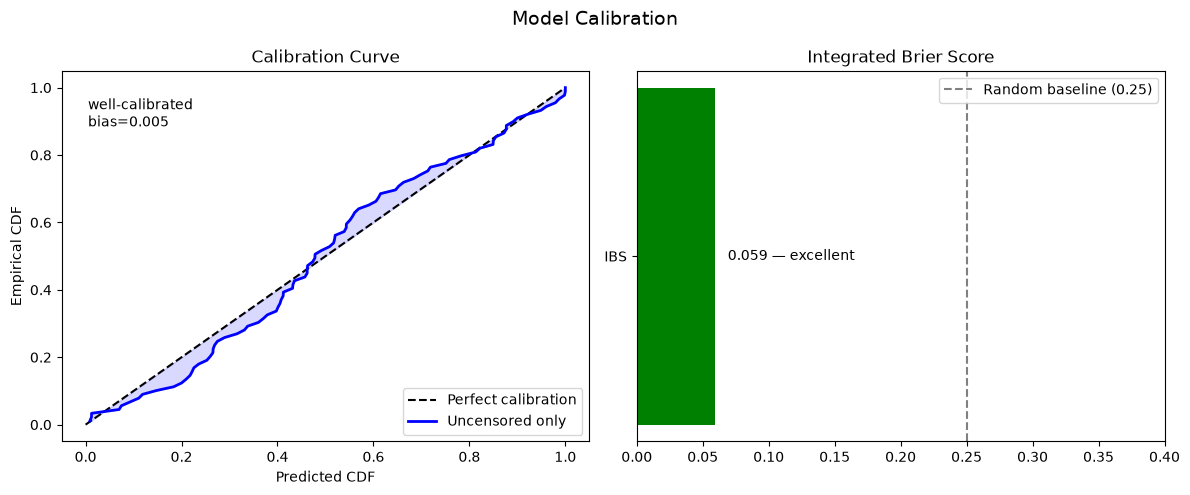

In [12]:
evaluation = model.evaluate(
    test_df,
    durations=test_labels_df['duration'].values,
    events=test_labels_df['event'].values,
)
print(f'C-index: {evaluation.c_index:.3f}')
print(f'RMSE:    {evaluation.rmse:.1f}')

evaluation.plot_calibration()
plt.show()

### Predicted against actual remaining life

One point per test engine: its actual remaining life against the
model's prediction. An engine whose actual remaining life is beyond
`max_rul` is plotted at `max_rul`, with its own marker, as RMSE counts
it. The closer the points lie to the diagonal, the better.

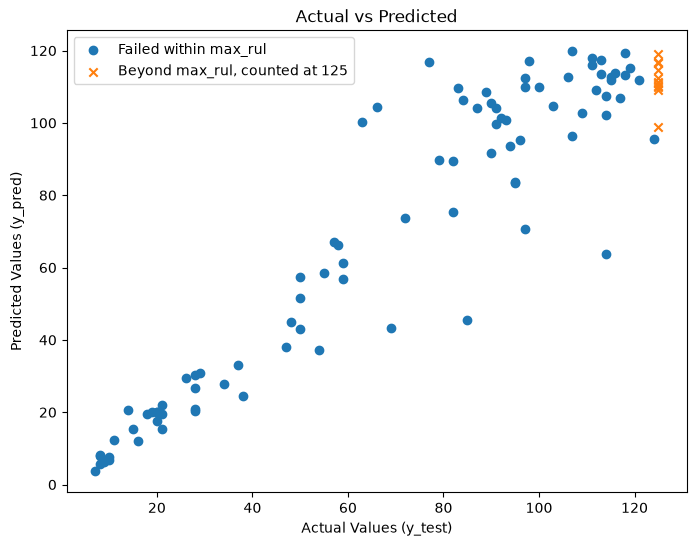

In [13]:
evaluation.plot_predictions()
plt.show()

## 9. Real-time endpoint

`deploy(endpoint_instance_type=...)` hosts the model on an endpoint,
which answers in seconds instead of starting a job. `predict()` then
goes through it, with the same results as batch transform. An endpoint
is billed for as long as it exists, so the next section deletes it.

In [14]:
model.deploy(endpoint_instance_type='ml.m5.large')

few = test_df[test_df['unit'].isin(units[:5])]
realtime = model.predict(few)
difference = float((realtime - curves.iloc[:, :5]).abs().max().max())
print(f'Largest difference from batch transform: {difference:.2e}')

🚀 Creating SageMaker Model for batch transform...
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker


📦 Model name: deepsurv-2026-10-28-19-02-01-158
✅ Model created successfully!
🌐 Creating endpoint deepsurv-2026-10-28-19-02-01-158 on ml.m5.large...


   Ready for real-time inference on endpoint deepsurv-2026-10-28-19-02-01-158

Next steps:
  mean_times = model.predict_mean(test_df)

🔮 Invoking endpoint deepsurv-2026-10-28-19-02-01-158 for 410 samples...


Largest difference from batch transform: 3.92e-06


## 10. Clean up

Delete the endpoint and the SageMaker model this notebook created, so
trying the product doesn't leave anything behind.

Training and transform jobs are billed for the time they ran and stop on
their own; there is nothing to delete for those.

In [15]:
model.delete()
print('Deleted', model_name)

Deleted deepsurv-2026-10-28-18-50-11-234


## Where to go next

- **Your own data**: rows per unit over time, with `unit`, `cycles`,
  `duration`, `event` and your features. On the free tier, train on at
  most 100 units.
- **Tuning**: add a range for any other setting, such as
  `'epochs': IntegerRange(20, 60)`, or raise `n_trials` to search longer.

Full documentation is in the SDK repository:
https://github.com/kooditurva/lifespan-predictor-sdk